# 17 - Publication figures

Paper-style figures for the thesis, produced read-only from the existing data pipeline. This notebook does **not** modify any file under `data/`, `out/`, `models/`, `scripts/`, `pinch_analysis/`, `thesis_analysis/`, or any other notebook -- it only writes PDF figures to `out_thesis/figs/pub/`.

**Part 1** recreates a representative subset of the exploratory/descriptive figures already produced by the `11`-`15` pipeline, redrawn in a consistent paper style. **Part 2** adds new figures analysing the experiment's free variables and comparing the raw vs. cleaned datasets, using `data/epoch_dataset_filtered`'s per-epoch metadata (plus `data/epoch_dataset` for the before/after-cleaning comparison).

Style rules applied to every figure below: vector PDF output; figures are drawn at their printed size -- single-column at `figsize=(COL_W, h)` (3.34 in, `\widthnarrow`), full-width at `figsize=(TEXT_W, h)` (7.09 in, `\textwidth`), from `paper_style.py` -- so LaTeX never rescales them; 7pt light sans-serif type (Roboto Light) with 7.5pt titles and 6pt legends, enforced on every saved figure; everything at column width except the SPN small multiples; the fixed 8-slot categorical palette in fixed order (never reordered, never cycled past 3 series without faceting); a light->dark blue sequential ramp for magnitude; a blue<->gray<->red diverging map centered at zero for signed/centered quantities (ERP topomaps); top/right spines dropped everywhere; thin (~0.5pt) dark bar edges; no dual y-axes; legends only for >=2 series (direct labelling otherwise).

## Setup

In [1]:
import pathlib, sys, os

ROOT = pathlib.Path.cwd()
if ROOT.name != 'DataAnalysis' and (ROOT.parent / 'DataAnalysis').exists():
    ROOT = ROOT.parent / 'DataAnalysis'
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print('Working directory:', pathlib.Path.cwd())

Working directory: C:\Users\nicol\github\VIBE\DataAnalysis


In [2]:
import json
import pickle

import mne
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from scripts.dataset_manager import read_raw_dataset

mne.set_log_level('WARNING')

RAW_DATASET = ROOT / 'data' / 'raw_dataset'
EPOCH_DATASET = ROOT / 'data' / 'epoch_dataset'              # pre-AutoReject
EPOCH_FILTERED = ROOT / 'data' / 'epoch_dataset_filtered'    # post-AutoReject (main Part-2 dataset)
RESULTS_DIR = ROOT / 'data' / 'results'
OUT_DIR = ROOT / 'out_thesis' / 'figs' / 'pub'
OUT_DIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    enforce_font_sizes(fig)
    path = OUT_DIR / name
    fig.savefig(path)
    print('wrote', path)

### Paper style: palette, fonts, chart chrome

In [3]:
from paper_style import (COL_W, TEXT_W, CAT_COLORS, BLUE_RAMP, SEQ_CMAP, DIV_CMAP, INK_PRIMARY, INK_SECONDARY,
                         GRID_COLOR, SPINE_COLOR, clean_axes, enforce_font_sizes)

### Shared data-loading helpers

`data/raw_dataset`, `data/epoch_dataset` (pre-AutoReject) and `data/epoch_dataset_filtered` (post-AutoReject) are large (3.7GB / 2.6GB / 270MB). Where a figure only needs epoch *counts* or *metadata* (class balance, free-variable flags, session duration, marker counts) we read with `preload=False` / read the small `markers.parquet` directly, never touching the bulk numeric arrays. Only the two figures that need actual signal (grand-average ERP, topomap, peak-to-peak amplitude) load `epoch_dataset_filtered` in full, via the project's own `read_raw_dataset` (the same helper `11`-`15` use), which is small enough (~370MB once merged) to hold in memory.

In [4]:
def iter_manifest(path):
    with open(path / 'manifest.json') as f:
        manifest = json.load(f)
    for subject in sorted(manifest):
        for session in sorted(manifest[subject]):
            yield subject, session, path / subject / session


def load_raw_stats(raw_dataset_path):
    """Session duration + marker/pinch-type counts, reading only markers.parquet
    and each raw .fif file's header (preload=False) -- no signal arrays touched."""
    dur_rows, marker_rows, pinchtype_rows = [], [], []
    for subject, session, sdir in iter_manifest(raw_dataset_path):
        raw = mne.io.read_raw_fif(sdir / 'eeg_raw.fif', preload=False, verbose=False)
        dur_rows.append(dict(subject=subject, session=session,
                              duration_s=raw.times[-1] - raw.times[0]))
        markers = pd.read_parquet(sdir / 'markers.parquet')
        for et, c in markers['EventType'].value_counts().items():
            marker_rows.append(dict(subject=subject, session=session, EventType=et, count=int(c)))
        pinch = markers[markers['EventType'] == 'PinchLog']
        if len(pinch) and 'PinchType' in pinch.columns:
            for pt, c in pinch['PinchType'].value_counts().items():
                pinchtype_rows.append(dict(subject=subject, session=session, PinchType=pt, count=int(c)))
    return pd.DataFrame(dur_rows), pd.DataFrame(marker_rows), pd.DataFrame(pinchtype_rows)


def load_epoch_metadata_lazy(epoch_dataset_path):
    """Epoch metadata only (mne.read_epochs preload=False) -- counts/flags without
    loading the (for epoch_dataset, ~2.6GB of) numeric signal arrays."""
    rows = []
    for subject, session, sdir in iter_manifest(epoch_dataset_path):
        ep = mne.read_epochs(sdir / 'session-epo.fif', preload=False, verbose=False)
        m = (ep.metadata.copy() if ep.metadata is not None
             else pd.DataFrame(index=range(len(ep)))).reset_index(drop=True)
        m['subject'] = subject
        m['session'] = session
        rows.append(m)
    return pd.concat(rows, ignore_index=True)


def merge_epochs_dict(epochs_dict):
    """Concatenate the {subject: {session: Epochs}} dict into one Epochs object,
    tagging each epoch's metadata with its subject/session (same helper 11-15 use)."""
    all_epochs = []
    for subj, sessions in epochs_dict.items():
        for sess, ep in sessions.items():
            ep = ep.copy()
            n = len(ep)
            if ep.metadata is None:
                ep.metadata = pd.DataFrame({'subject': [subj] * n, 'session': [sess] * n})
            else:
                meta = ep.metadata.copy()
                meta['subject'] = subj
                meta['session'] = sess
                ep.metadata = meta
            all_epochs.append(ep)
    return mne.concatenate_epochs(all_epochs)

## Part 1: recreating the exploratory figures, in paper style

### 1a. Data-quality overview

Recreates `12_data_quality_analysis.ipynb`, cell "`plot_eeg_stats`" (also saved as `DataAnalysis/eeg_stats_overview.png`) as four separate, individually clean figures instead of one crowded 2x2 panel. Two deviations from the original, noted here rather than silently:

1. The original's bottom-right panel ("# Bad Electrodes") reads `n_bad` from `raw.info['bads']`, which is never populated at the raw-data stage on disk (pyprep-based bad-channel detection in `12` is only ever run interactively on single example sessions, not persisted per-session) -- every cell in that panel is 0. Re-running that panel would just reproduce an all-zero heatmap, so it is replaced here with a more informative and directly comparable quality-prevalence proxy: the per-participant AutoReject epoch-rejection rate (the same rejection step `12`, cell "`autoreject_report`", performs to build `epoch_dataset_filtered`), computed cheaply from the epoch counts already on disk rather than by re-running AutoReject.
2. The original's bottom-left panel ("Mean Count per PinchType") is empty ("No PinchType data") because it filters `markers['EventType'] == 'PinchType'`, which never matches (the actual value is `'PinchLog'`). Fixed below.

In [5]:
dur_df, marker_df, pinchtype_df = load_raw_stats(RAW_DATASET)
print('sessions:', dur_df.shape[0], ' subjects:', dur_df['subject'].nunique())
all_sessions = dur_df[['subject', 'session']].drop_duplicates()

sessions: 31  subjects: 16


pre-AR epochs: 51899  post-AR epochs: 5647
wrote C:\Users\nicol\github\VIBE\DataAnalysis\out_thesis\figs\pub\dataquality_autoreject_droprate.pdf


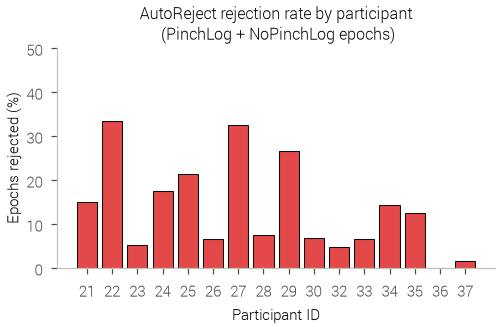

In [6]:
md_pre = load_epoch_metadata_lazy(EPOCH_DATASET)
md_post_lazy = load_epoch_metadata_lazy(EPOCH_FILTERED)
print('pre-AR epochs:', md_pre.shape[0], ' post-AR epochs:', md_post_lazy.shape[0])

pre_counts = (md_pre[md_pre['EventType'].isin(['PinchLog', 'NoPinchLog'])]
              .groupby('subject').size().rename('n_pre'))
post_counts = md_post_lazy.groupby('subject').size().rename('n_post')
cmp_df = pd.concat([pre_counts, post_counts], axis=1).fillna(0)
cmp_df['drop_rate'] = 1 - cmp_df['n_post'] / cmp_df['n_pre']
cmp_df = cmp_df.sort_index(key=lambda s: [int(x.split('_')[1]) for x in s])

fig, ax = plt.subplots(figsize=(COL_W, 2.2))
x = np.arange(len(cmp_df))
ax.bar(x, cmp_df['drop_rate'] * 100, color=CAT_COLORS[7], edgecolor=INK_PRIMARY, linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels([s.replace('subject_', '') for s in cmp_df.index])
ax.set_xlabel('Participant ID')
ax.set_ylabel('Epochs rejected (%)')
ax.set_ylim(0,50)
ax.set_title('AutoReject rejection rate by participant\n (PinchLog + NoPinchLog epochs)')
clean_axes(ax)
fig.tight_layout(pad=0.3)
savefig(fig, 'dataquality_autoreject_droprate.pdf')
plt.show()

### 1b. Grand-average ERP and topomap sequence

Loads the full `data/epoch_dataset_filtered` (post-AutoReject) with signal data via the project's own `read_raw_dataset` + `merge_epochs_dict` -- the same pattern `12`/`13`/`15` use -- and applies the same channel-wise mean-normalization step `13_free_variable_comparison.ipynb` applies before plotting from this dataset. This merged, normalized `epochs` object (and its `.metadata` as `md`) is reused for every remaining figure in this notebook, including all of Part 2.

In [7]:
epochs_dict = read_raw_dataset(EPOCH_FILTERED)
epochs = merge_epochs_dict(epochs_dict)
epochs.apply_function(lambda x: (x - x.mean()), channel_wise=True)  # matches 13's own normalization

md = epochs.metadata
times = epochs.times
n_subjects = md['subject'].nunique()
print(epochs)
print(f'{n_subjects} participants, tmin={epochs.tmin}s, tmax={epochs.tmax}s')

C:\Users\nicol\AppData\Local\Temp\ipykernel_10160\4017154873.py:57: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  return mne.concatenate_epochs(all_epochs)


<EpochsArray | 5647 events (all good), -1.7 – 0.3 s (baseline -1.7 – 0 s), ~543.8 MiB, data loaded, with metadata,
 'PinchLog': 3144
 'NoPinchLog': 2503>
16 participants, tmin=-1.7s, tmax=0.3s


**Figure: grand-average ERP, Pinch vs. No-Pinch, at C3 and Cz.** Mean epoch amplitude (shaded band = +/-1 SEM across epochs) time-locked to pinch onset (t=0), for true `PINCH` trials vs. `NoPinchLog` control epochs, at two motor-relevant electrodes. A central negative deflection builds up over C3/Cz in the run-up to a pinch and is absent for the no-pinch control, consistent with a movement-related (Bereitschaftspotential-like) cortical potential; No-Pinch epochs stay close to their own zero-mean baseline throughout, as expected.

*Based on: `13_free_variable_comparison.ipynb`, cell `plot_compare_evokeds_grid(..., group_by="EventType")` ("Pinch vs No Pinch" section) -- redrawn as a compact 2-channel comparison instead of the full 20-channel grid.*

n_pinch 2261 n_nopinch 2503 n_pinch_choice 483
wrote C:\Users\nicol\github\VIBE\DataAnalysis\out_thesis\figs\pub\erp_pinch_vs_nopinch.pdf


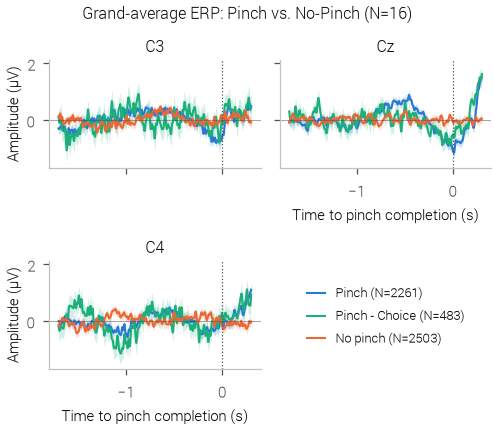

In [8]:
picks = ['C3', 'Cz', 'C4']
mask_pinch = ((md['EventType'] == 'PinchLog') & (md['PinchType'] == 'PINCH')).values
mask_nopinch = (md['EventType'] == 'NoPinchLog').values
mask_pinch_choice = ((md['EventType'] == 'PinchLog') & (md['PinchType'] == 'PINCH') & md['isChoiceStimuli']).values
n_pinch, n_nopinch, n_pinch_choice = int(mask_pinch.sum()), int(mask_nopinch.sum()), int(mask_pinch_choice.sum())
print('n_pinch', n_pinch, 'n_nopinch', n_nopinch, 'n_pinch_choice', n_pinch_choice)

data_erp = epochs.get_data(picks=picks) * 1e6  # volts -> microvolts

fig, axes = plt.subplots(2, 2, figsize=(COL_W, 2.9), sharex=True, sharey=True, layout='constrained')
axes = axes.ravel()
groups = {f'Pinch (N={n_pinch})': (mask_pinch, CAT_COLORS[0]), f'Pinch - Choice (N={n_pinch_choice})': (mask_pinch_choice, CAT_COLORS[2]), f'No pinch (N={n_nopinch})': (mask_nopinch, CAT_COLORS[1])}
for col, ch in enumerate(picks):
    ax = axes[col]
    for label, (mask, color) in groups.items():
        d = data_erp[mask, col, :]
        m = d.mean(axis=0)
        sem = d.std(axis=0, ddof=1) / np.sqrt(d.shape[0])
        ax.plot(times, m, color=color, linewidth=1, label=label)
        ax.fill_between(times, m - sem, m + sem, color=color, alpha=0.2, linewidth=0)
    ax.axvline(0, color=INK_SECONDARY, linewidth=0.6, linestyle=':')
    ax.axhline(0, color=INK_SECONDARY, linewidth=0.5, alpha=0.5)
    ax.set_title(ch)
    clean_axes(ax)
axes[0].set_ylabel('Amplitude (\u00b5V)')
axes[2].set_ylabel('Amplitude (\u00b5V)')
for ax in axes[1:3]:
    ax.set_xlabel('Time to pinch completion (s)')
axes[1].tick_params(labelbottom=True)  # the panel below it holds the legend
axes[-1].set_axis_off()
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc='center', frameon=False)
fig.suptitle(f'Grand-average ERP: Pinch vs. No-Pinch (N={n_subjects})')
savefig(fig, 'erp_pinch_vs_nopinch.pdf')
plt.show()

n_pinch 2261 n_wizard_of_oz 528
wrote C:\Users\nicol\github\VIBE\DataAnalysis\out_thesis\figs\pub\erp_pinch_vs_hinted.pdf


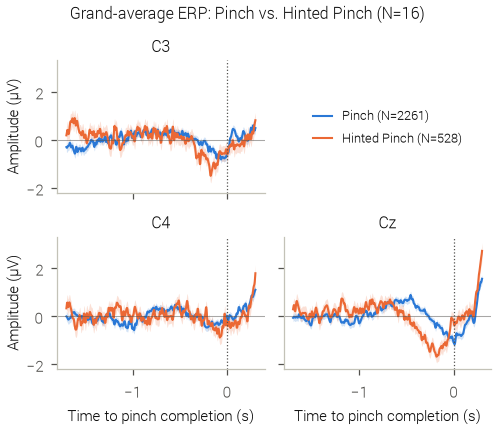

In [9]:
picks = ['C3', 'Cz', 'C4']
mask_pinch = ((md['EventType'] == 'PinchLog') & (md['PinchType'] == 'PINCH')).values
mask_nopinch = ((md['EventType'] == 'PinchLog') & (md['PinchType'] == 'PINCH_WIZARD_OF_OZ')).values
n_pinch, n_nopinch = int(mask_pinch.sum()), int(mask_nopinch.sum())
print('n_pinch', n_pinch, 'n_wizard_of_oz', n_nopinch)

data_erp = epochs.get_data(picks=picks) * 1e6  # volts -> microvolts

fig, axes = plt.subplots(2, 2, figsize=(COL_W, 2.9), sharex=True, sharey=True, layout='constrained')
axes = axes.ravel()
groups = {f'Pinch (N={n_pinch})': (mask_pinch, CAT_COLORS[0]), f'Hinted Pinch (N={n_nopinch})': (mask_nopinch, CAT_COLORS[1])}
PANEL = {'C3': 0, 'C4': 2, 'Cz': 3}  # axes[1] (top right) holds the legend
for col, ch in enumerate(picks):
    ax = axes[PANEL[ch]]
    for label, (mask, color) in groups.items():
        d = data_erp[mask, col, :]
        m = d.mean(axis=0)
        sem = d.std(axis=0, ddof=1) / np.sqrt(d.shape[0])
        ax.plot(times, m, color=color, linewidth=1, label=label)
        ax.fill_between(times, m - sem, m + sem, color=color, alpha=0.2, linewidth=0)
    ax.axvline(0, color=INK_SECONDARY, linewidth=0.6, linestyle=':')
    ax.axhline(0, color=INK_SECONDARY, linewidth=0.5, alpha=0.5)
    ax.set_title(ch)
    clean_axes(ax)
axes[0].set_ylabel('Amplitude (\u00b5V)')
axes[2].set_ylabel('Amplitude (\u00b5V)')
for ax in axes[2:]:
    ax.set_xlabel('Time to pinch completion (s)')
axes[1].set_axis_off()
handles, labels = axes[0].get_legend_handles_labels()
axes[1].legend(handles, labels, loc='center', frameon=False)
fig.suptitle(f'Grand-average ERP: Pinch vs. Hinted Pinch (N={n_subjects})')
savefig(fig, 'erp_pinch_vs_hinted.pdf')
plt.show()

**Figure: topomap sequence, PINCH trials.** Scalp distribution of the grand-average PINCH-trial ERP at five timepoints from -0.6s to +0.2s around pinch onset, diverging colormap centered at 0ÂµV (blue = negative, red = positive). A central negativity emerges and peaks close to t=0, spatially consistent with the C3/Cz time-course above.

*Based on: `13_free_variable_comparison.ipynb`, cell `plot_joint_grouped(..., group_by="EventType")` ("Pinch vs No Pinch" section, topomap-sequence part of `ev.plot_joint`) -- redrawn as a standalone topomap strip (the joint line plot is covered by the ERP figure above) with the diverging palette in place of the default colormap.*

wrote C:\Users\nicol\github\VIBE\DataAnalysis\out_thesis\figs\pub\topomap_pinch_sequence.pdf


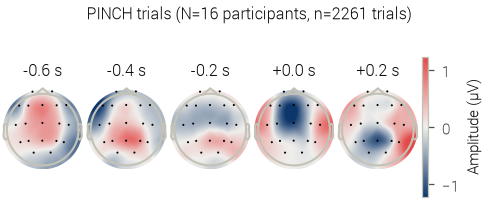

In [10]:
ev_pinch = epochs[mask_pinch].average()
ref_chs = [c for c in ev_pinch.ch_names if c not in ('A1', 'A2')]  # drop mastoid refs from the scalp map
ev_topo = ev_pinch.copy().pick(ref_chs)

show_times = [t for t in [-0.6, -0.4, -0.2, 0.0, 0.2] if ev_topo.tmin <= t <= ev_topo.tmax]
sel_idx = [np.argmin(np.abs(ev_topo.times - t)) for t in show_times]
topo_data = ev_topo.data * 1e6
vmax = np.abs(topo_data[:, sel_idx]).max()

fig, axes = plt.subplots(1, len(show_times) + 1, figsize=(COL_W, 1.35),
                          gridspec_kw={'width_ratios': [1] * len(show_times) + [0.08]})
for ax, idx, t in zip(axes[:-1], sel_idx, show_times):
    im, _ = mne.viz.plot_topomap(
        topo_data[:, idx], ev_topo.info, axes=ax, show=False,
        cmap=DIV_CMAP, vlim=(-vmax, vmax), sensors=True, contours=0,
    )
    ax.set_title(f'{t:+.1f} s')
cbar = fig.colorbar(im, cax=axes[-1])
cbar.set_label('Amplitude (\u00b5V)')
fig.suptitle(f'PINCH trials (N={n_subjects} participants, n={n_pinch} trials)')
fig.tight_layout(pad=0.3, rect=[0, 0, 1, 0.86])
savefig(fig, 'topomap_pinch_sequence.pdf')
plt.show()

### 1c. Model comparison across evaluation splits

Reads the cached LOSO summary already computed for the thesis (`out_thesis/model_metrics_loso.csv`, produced from `data/results/{rf,eegnet,transformer}_leave_one_out_run.pkl` -- see `thesis_analysis/16_feedback_and_significance_analysis.ipynb`) for the Leave-One-Out bars, and loads only the small `general_run`/`cross_session_run` result pickles directly for the Mixed and Cross-Session bars, avoiding the 200-360MB `leave_one_out_run.pkl` files.

**Figure: pinch-detection accuracy by model and evaluation split.** Test accuracy for the three models (RandomForest/EEGForest, EEGNet, GAT-GRU-Transformer) under a mixed (in-distribution) split, leave-one-subject-out cross-validation, and a cross-session split, with the majority-class chance level (from the LOSO confusion matrices) as a reference line. EEGNet is the strongest and most consistent model across all three splits; leave-one-out and cross-session accuracy are both noticeably lower than the mixed split for every model, showing that subject- and session-generalization is harder than in-distribution classification.

*Based on: `15_results_analysis.ipynb`, cell `plot_overall_performance_comparison` ("model comparison - overall").*

In [11]:
from models.EEGNet import EEGNet, ConstrainedConv2d, ConstrainedLinear
from models.GATGRU import MultiBranchGATGRUTransformer, SpatialBranch, FrequencyBranch, TemporalBranch, GATLayer

def load_cached(name):
    with open(RESULTS_DIR / f'{name}.pkl', 'rb') as fh:
        cached = pickle.load(fh)
    return cached['result']

rf_general, _ = load_cached('rf_general_run')
rf_cross_session, _ = load_cached('rf_cross_session_run')
eegnet_general, _ = load_cached('eegnet_general_run')
eegnet_cross_session, _ = load_cached('eegnet_cross_session_run')
transformer_general = load_cached('transformer_general_run')
transformer_cross_session, _ = load_cached('transformer_cross_session_run')

loso_csv = pd.read_csv(OUT_DIR.parent.parent / 'model_metrics_loso.csv')
loso_csv

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from C:\Users\nicol\_netrc.
wandb: Currently logged in as: nbaeriswyl (nbaeriswyl-eth-z-rich) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


,model,accuracy_mean,accuracy_std,pooled_accuracy,precision,recall,f1,fpr,chance_mean,n_pooled,tp,fn,fp,tn
0,RF,0.623217,0.037432,0.624044,0.616960,0.572755,0.594037,0.328566,0.531904,4708,1295,966,804,1643
1,EEGNet,0.672792,0.059634,0.667375,0.657596,0.641309,0.649351,0.308541,0.531904,4708,1450,811,755,1692
2,Transformer,0.627473,0.061338,0.623195,0.617463,0.566121,0.590678,0.324070,0.531904,4708,1280,981,793,1654


wrote C:\Users\nicol\github\VIBE\DataAnalysis\out_thesis\figs\pub\model_comparison_by_split.pdf


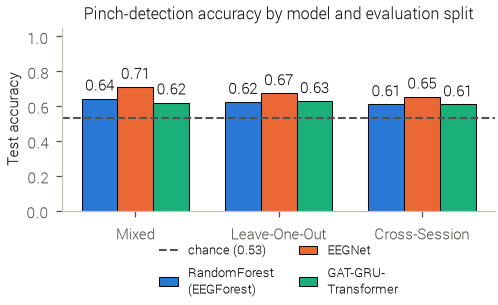

In [12]:
model_names = ['RF', 'EEGNet', 'Transformer']
pretty = {'RF': 'RandomForest\n(EEGForest)', 'EEGNet': 'EEGNet', 'Transformer': 'GAT-GRU-\nTransformer'}
splits = ['Mixed', 'Leave-One-Out', 'Cross-Session']

acc = {
    'RF': [rf_general['test_accuracy'],
           loso_csv.loc[loso_csv.model == 'RF', 'accuracy_mean'].item(),
           rf_cross_session['test_accuracy']],
    'EEGNet': [eegnet_general['test_accuracy'],
               loso_csv.loc[loso_csv.model == 'EEGNet', 'accuracy_mean'].item(),
               eegnet_cross_session['test_accuracy']],
    'Transformer': [transformer_general['test_accuracy'],
                    loso_csv.loc[loso_csv.model == 'Transformer', 'accuracy_mean'].item(),
                    transformer_cross_session['test_accuracy']],
}
chance_loso = loso_csv['chance_mean'].iloc[0]

fig, ax = plt.subplots(figsize=(COL_W, 2.1))
x = np.arange(len(splits))
width = 0.25
for i, m in enumerate(model_names):
    bars = ax.bar(x + (i - 1) * width, acc[m], width, color=CAT_COLORS[i],
                   edgecolor=INK_PRIMARY, linewidth=0.5, label=pretty[m])
    ax.bar_label(bars, fmt='%.2f', padding=2)
ax.axhline(chance_loso, color=INK_SECONDARY, linestyle='--', linewidth=1,
           label=f'chance ({chance_loso:.2f})')
ax.set_xticks(x)
ax.set_xticklabels(splits)
ax.set_ylabel('Test accuracy')
ax.set_ylim(0, 1.05)
ax.set_title('Pinch-detection accuracy by model and evaluation split')
ax.legend(frameon=False, loc='upper center', ncol=2, bbox_to_anchor=(0.5, -0.12))
clean_axes(ax)
fig.tight_layout(pad=0.3)
savefig(fig, 'model_comparison_by_split.pdf')
plt.show()

## Part 2: free-variable and dataset analysis

New figures (not recreations), built from `epochs`/`md` loaded above (`data/epoch_dataset_filtered`, post-AutoReject). Confirmed metadata columns for the free variables: `hasVisualFeedback`, `hasAuditoryFeedback`, `hasVirtualHand`, `feedbackIsDelayed`, `pinchIsHinted`, `isChoiceStimuli` (all boolean, `None`/NaN on `NoPinchLog` epochs where they're undefined) and `numberOfStimuli` (a 3-way categorical stimulus-layout size: 1, 4, or 6 stimuli), plus `subject` and `session` as the subject/session identifiers added by `merge_epochs_dict`. All free-variable and stimulus-layout figures below are restricted to real `PINCH` trials (`EventType == 'PinchLog' & PinchType == 'PINCH'`), the only epochs on which every flag is defined.

In [13]:
FREE_VARS = ['hasVisualFeedback', 'hasAuditoryFeedback', 'hasVirtualHand',
             'feedbackIsDelayed', 'pinchIsHinted', 'isChoiceStimuli']
PRETTY = {
    'hasVisualFeedback': 'Visual feedback',
    'hasAuditoryFeedback': 'Auditory feedback',
    'hasVirtualHand': 'Virtual hand',
    'feedbackIsDelayed': 'Delayed feedback',
    'pinchIsHinted': 'Pinch hinted',
    'isChoiceStimuli': 'Choice stimuli',
}

pinch_mask = ((md['EventType'] == 'PinchLog') & (md['PinchType'] == 'PINCH')).values
ch = 'C3'
data_c3 = epochs.get_data(picks=[ch])[:, 0, :] * 1e6  # (n_epochs, n_times), microvolts

**Figure: feedback free variables at the SPN electrodes where feedback enlarges the SPN (small multiples).** Grand-average ERP (+/-1 SEM) for flag=True vs. flag=False, restricted to real PINCH trials, for the three feedback variables (visual feedback, auditory feedback, virtual hand). Candidate electrodes are the 15 on which the stimulus-preceding negativity (SPN) is typically recorded (Brunia & van Boxtel 2001; Böcker et al. 1994; the same `SPN` set used for the SPN features in `models/EEGForest.py`). Only the electrodes where the SPN is larger *with* the modality than without it, for **all three** modalities, are shown, so every row shows the same electrodes. "Larger SPN" means a more negative mean amplitude in the late SPN window (-0.2 to 0 s before the pinch, shaded; the same late window `spn_features` uses). All panels share one y-axis.

The selection is a descriptive filter on grand averages, not a statistical test, and it depends on the window: with -0.5 to 0 s a different, smaller set passes, and with -1.0 to 0 s none does. The per-electrode True-minus-False differences are printed below the figure code for reference.

True - False mean amplitude in (-0.2, 0.0) s (µV; negative = larger SPN with the modality):
    hasVisualFeedback  hasAuditoryFeedback  hasVirtualHand  larger_for_all
F7              0.750                0.103           0.112           False
F3             -0.295               -0.320          -0.370            True
Fz             -0.794               -0.549          -0.366            True
F4             -0.655               -0.019          -0.334            True
F8             -0.294               -0.042          -0.194            True
T7             -0.074                0.247          -0.017           False
C3             -0.309               -0.041          -0.351            True
Cz             -0.336                0.044          -0.016           False
C4             -0.478                0.143          -0.124           False
T8             -0.044                0.125          -0.128           False
P7             -0.165                0.162           0.483           False
P3      

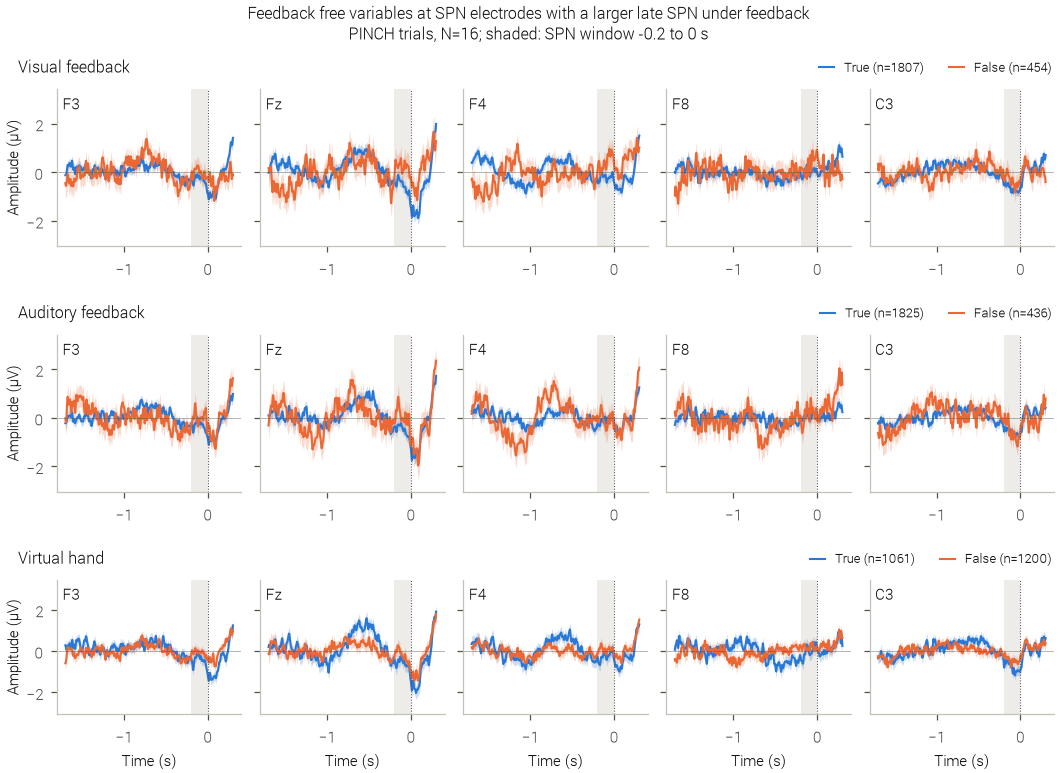

In [14]:
SPN_GRID = [['F7', 'F3', 'Fz', 'F4', 'F8'],
            ['T7', 'C3', 'Cz', 'C4', 'T8'],
            ['P7', 'P3', 'Pz', 'P4', 'P8']]
SPN_VARS = ['hasVisualFeedback', 'hasAuditoryFeedback', 'hasVirtualHand']
SPN_WINDOW = (-0.2, 0.0)  # late SPN window, s relative to the pinch (same as spn_features)

spn_chs = [c for row in SPN_GRID for c in row]  # scalp order: frontal -> parietal, left -> right
data_spn = epochs.get_data(picks=spn_chs) * 1e6  # (n_epochs, 15, n_times), microvolts
win_mask = (times >= SPN_WINDOW[0]) & (times <= SPN_WINDOW[1])

# SPN amplitude = mean amplitude in the late window; "larger SPN" = more negative, so an electrode
# is kept only if True - False < 0 for every feedback modality
masks = {var: (pinch_mask & (md[var].values == True), pinch_mask & (md[var].values == False))
         for var in SPN_VARS}
spn_diff = pd.DataFrame({
    var: data_spn[m_t][:, :, win_mask].mean((0, 2)) - data_spn[m_f][:, :, win_mask].mean((0, 2))
    for var, (m_t, m_f) in masks.items()
}, index=spn_chs)
spn_diff['larger_for_all'] = (spn_diff[SPN_VARS] < 0).all(axis=1)
print(f'True - False mean amplitude in {SPN_WINDOW} s (\u00b5V; negative = larger SPN with the modality):')
print(spn_diff.round(3).to_string())
sel_chs = spn_diff.index[spn_diff['larger_for_all']].tolist()
print('\nselected electrodes:', sel_chs)
if not sel_chs:
    raise ValueError(f'no SPN electrode shows a larger SPN with all three modalities in {SPN_WINDOW}')

def mean_sem(d):
    return d.mean(0), d.std(0, ddof=1) / np.sqrt(d.shape[0])

spn_lines = {}
y_lo, y_hi = np.inf, -np.inf
for var, (m_t, m_f) in masks.items():
    for c in sel_chs:
        ci = spn_chs.index(c)
        (mt, st), (mf, sf) = mean_sem(data_spn[m_t, ci]), mean_sem(data_spn[m_f, ci])
        spn_lines[var, c] = (mt, st, mf, sf)
        y_lo = min(y_lo, (mt - st).min(), (mf - sf).min())
        y_hi = max(y_hi, (mt + st).max(), (mf + sf).max())
pad = 0.1 * (y_hi - y_lo)

n_cols = min(len(sel_chs), 5)
n_rows = int(np.ceil(len(sel_chs) / n_cols))
fig = plt.figure(figsize=(TEXT_W, 0.4 + len(SPN_VARS) * (0.35 + 1.25 * n_rows)), layout='constrained')
subfigs = np.atleast_1d(fig.subfigures(len(SPN_VARS), 1, hspace=0.04))
for sf_, var in zip(subfigs, SPN_VARS):
    # identical y-limits are set on every panel below, so the scale is shared across modalities too
    axes = np.atleast_2d(sf_.subplots(n_rows, n_cols, sharex=True, sharey=True, squeeze=False))
    n_t, n_f = int(masks[var][0].sum()), int(masks[var][1].sum())
    for i, ax in enumerate(axes.ravel()):
        if i >= len(sel_chs):
            ax.set_axis_off()
            continue
        c = sel_chs[i]
        mt, st, mf, sf = spn_lines[var, c]
        ax.axvspan(*SPN_WINDOW, color=GRID_COLOR, alpha=0.6, linewidth=0)
        ax.plot(times, mt, color=CAT_COLORS[0], linewidth=1.0, label=f'True (n={n_t})')
        ax.fill_between(times, mt - st, mt + st, color=CAT_COLORS[0], alpha=0.25, linewidth=0)
        ax.plot(times, mf, color=CAT_COLORS[1], linewidth=1.0, label=f'False (n={n_f})')
        ax.fill_between(times, mf - sf, mf + sf, color=CAT_COLORS[1], alpha=0.25, linewidth=0)
        ax.axvline(0, color=INK_SECONDARY, linewidth=0.5, linestyle=':')
        ax.axhline(0, color=INK_SECONDARY, linewidth=0.4, alpha=0.5)
        ax.set_ylim(y_lo - pad, y_hi + pad)
        ax.text(0.03, 0.97, c, transform=ax.transAxes, ha='left', va='top', color=INK_PRIMARY)
        clean_axes(ax)
    for ax in axes[:, 0]:
        ax.set_ylabel('Amplitude (\u00b5V)')
    if var == SPN_VARS[-1]:  # time axis is shared by all modalities, label it once at the bottom
        for ax in axes[-1, :]:
            ax.set_xlabel('Time (s)')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    sf_.suptitle(PRETTY[var], x=0.02, ha='left')
    sf_.legend(handles, labels, loc='upper right', ncol=2, frameon=False, handlelength=1.2)

fig.suptitle(f'Feedback free variables at SPN electrodes with a larger late SPN under feedback\n'
             f'PINCH trials, N={n_subjects}; shaded: SPN window {SPN_WINDOW[0]:g} to {SPN_WINDOW[1]:g} s')
savefig(fig, 'freevar_erp_spn_smallmultiples.pdf')
plt.show()

**Figure: class balance of the boolean free variables.** Epoch counts for True vs. False for each free variable (PINCH trials only, N=15 participants). Visual/auditory feedback are present on ~80% of trials; virtual hand is roughly balanced; delayed feedback, hinting and choice stimuli are all deliberately rare manipulations (10-24% True), so their ERP averages rest on far fewer trials than the feedback variables'.

wrote C:\Users\nicol\github\VIBE\DataAnalysis\out_thesis\figs\pub\freevar_epoch_counts.pdf


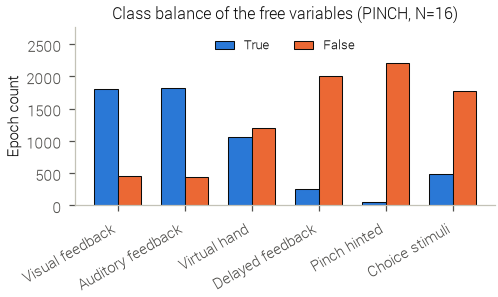

In [15]:
fig, ax = plt.subplots(figsize=(COL_W, 2))
x = np.arange(len(FREE_VARS))
width = 0.35
counts_true = [int((pinch_mask & (md[v].values == True)).sum()) for v in FREE_VARS]
counts_false = [int((pinch_mask & (md[v].values == False)).sum()) for v in FREE_VARS]
ax.bar(x - width / 2, counts_true, width, color=CAT_COLORS[0], edgecolor=INK_PRIMARY, linewidth=0.5, label='True')
ax.bar(x + width / 2, counts_false, width, color=CAT_COLORS[1], edgecolor=INK_PRIMARY, linewidth=0.5, label='False')
ax.set_xticks(x)
ax.set_xticklabels([PRETTY[v] for v in FREE_VARS], rotation=30, ha='right')
ax.set_ylabel('Epoch count')
ax.set_title(f'Class balance of the free variables (PINCH, N={n_subjects})')
ax.set_ylim(top=max(counts_true + counts_false) * 1.25)  # room for the legend
ax.legend(frameon=False, loc='upper center', ncols=2)
clean_axes(ax)
fig.tight_layout(pad=0.3)
savefig(fig, 'freevar_epoch_counts.pdf')
plt.show()

**Figure: stimulus-layout size (numberOfStimuli).** Left: epoch count for each of the three stimulus-layout sizes (1/4/6 candidate stimuli on screen). Right: grand-average C3 ERP for the same three groups. The 4- and 6-stimulus layouts (the two "real" multi-target conditions) track each other closely; the 1-stimulus layout (trivial/no-choice trials, smallest n) is visibly noisier and diverges most from baseline, consistent with it being the least-sampled condition.

wrote C:\Users\nicol\github\VIBE\DataAnalysis\out_thesis\figs\pub\numberofstimuli_layout.pdf


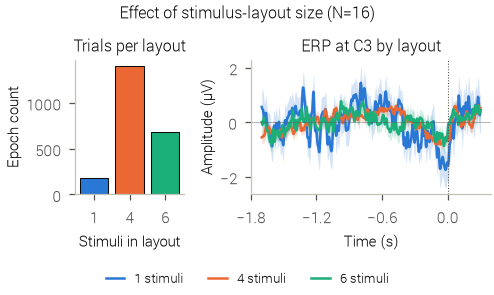

In [16]:
levels = sorted(md.loc[pinch_mask, 'numberOfStimuli'].dropna().unique())

fig, axes = plt.subplots(1, 2, figsize=(COL_W, 2.0), layout='constrained', gridspec_kw={'width_ratios': [1, 2.2]})
ax = axes[0]
level_counts = [int((pinch_mask & (md['numberOfStimuli'] == lv)).sum()) for lv in levels]
ax.bar([str(int(lv)) for lv in levels], level_counts, color=CAT_COLORS[:len(levels)],
       edgecolor=INK_PRIMARY, linewidth=0.5)
ax.set_xlabel('Stimuli in layout')
ax.set_ylabel('Epoch count')
ax.set_title('Trials per layout')
clean_axes(ax)

ax = axes[1]
for i, lv in enumerate(levels):
    m = pinch_mask & (md['numberOfStimuli'] == lv)
    d = data_c3[m]
    mean_, sem_ = d.mean(0), d.std(0, ddof=1) / np.sqrt(d.shape[0])
    ax.plot(times, mean_, color=CAT_COLORS[i], linewidth=1.2, label=f'{int(lv)} stimuli')
    ax.fill_between(times, mean_ - sem_, mean_ + sem_, color=CAT_COLORS[i], alpha=0.2, linewidth=0)
ax.axvline(0, color=INK_SECONDARY, linewidth=0.5, linestyle=':')
ax.axhline(0, color=INK_SECONDARY, linewidth=0.4, alpha=0.5)
ax.set_xlabel('Time (s)')
ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(4))
ax.set_ylabel('Amplitude (\u00b5V)')
ax.set_title(f'ERP at {ch} by layout')
fig.legend(*ax.get_legend_handles_labels(), frameon=False, loc='outside lower center', ncols=len(levels))
clean_axes(ax)
fig.suptitle(f'Effect of stimulus-layout size (N={n_subjects})')
savefig(fig, 'numberofstimuli_layout.pdf')
plt.show()

### Dataset comparisons

**Figure: session 1 vs. session 2.** Left: total epoch count. Right: class balance (share of `PinchLog` vs. `NoPinchLog` epochs). Session 1 contributes more than twice as many epochs as session 2 (consistent with its longer duration, see the data-quality section), but the Pinch/No-Pinch class balance is essentially unchanged between sessions.

wrote C:\Users\nicol\github\VIBE\DataAnalysis\out_thesis\figs\pub\dataset_session1_vs_session2.pdf


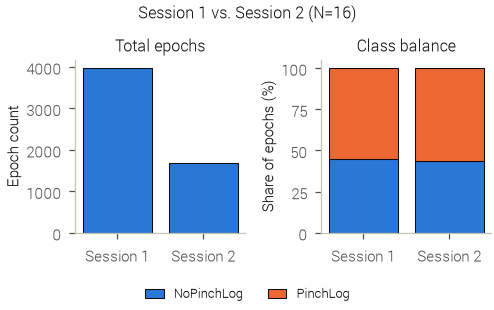

In [17]:
sess_counts = md.groupby('session').size()
sess_class = md.groupby(['session', 'EventType']).size().unstack(fill_value=0)
sess_class_frac = sess_class.div(sess_class.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(COL_W, 2.1), layout='constrained')
ax = axes[0]
ax.bar(sess_counts.index.str.replace('session_', 'Session '), sess_counts.values,
       color=CAT_COLORS[0], edgecolor=INK_PRIMARY, linewidth=0.5)
ax.set_ylabel('Epoch count')
ax.set_title('Total epochs')
clean_axes(ax)

ax = axes[1]
sess_labels = sess_class_frac.index.str.replace('session_', 'Session ')
bottom = np.zeros(len(sess_class_frac))
for i, evtype in enumerate(sess_class_frac.columns):
    vals = sess_class_frac[evtype].values * 100
    ax.bar(sess_labels, vals, bottom=bottom, color=CAT_COLORS[i], edgecolor=INK_PRIMARY,
           linewidth=0.5, label=evtype)
    bottom += vals
ax.set_ylabel('Share of epochs (%)')
ax.set_title('Class balance')
fig.legend(*ax.get_legend_handles_labels(), frameon=False, loc='outside lower center', ncols=2)
clean_axes(ax)
fig.suptitle(f'Session 1 vs. Session 2 (N={n_subjects})')
savefig(fig, 'dataset_session1_vs_session2.pdf')
plt.show()

**Figure: epochs retained before vs. after AutoReject cleaning.** Per-participant `PinchLog`+`NoPinchLog` epoch counts in `data/epoch_dataset` (before) vs. `data/epoch_dataset_filtered` (after), for the 14 participants AutoReject retains at least some data for. This is the same underlying before/after comparison as the AutoReject-rejection-rate figure in Part 1, shown here as absolute counts (rather than a rate) to make clear how many trials are actually lost per participant.

wrote C:\Users\nicol\github\VIBE\DataAnalysis\out_thesis\figs\pub\dataset_before_after_autoreject.pdf


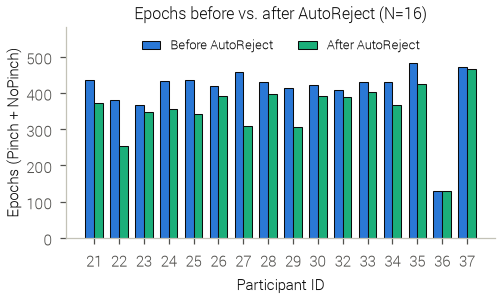

In [18]:
cmp_df2 = cmp_df.loc[[s for s in cmp_df.index if s in md['subject'].unique()]]
cmp_df2 = cmp_df2.sort_index(key=lambda s: [int(x.split('_')[1]) for x in s])

fig, ax = plt.subplots(figsize=(COL_W, 2.0))
x = np.arange(len(cmp_df2))
width = 0.35
ax.bar(x - width / 2, cmp_df2['n_pre'], width, color=CAT_COLORS[0], edgecolor=INK_PRIMARY, linewidth=0.5, label='Before AutoReject')
ax.bar(x + width / 2, cmp_df2['n_post'], width, color=CAT_COLORS[2], edgecolor=INK_PRIMARY, linewidth=0.5, label='After AutoReject')
ax.set_xticks(x)
ax.set_xticklabels([s.replace('subject_', '') for s in cmp_df2.index])
ax.set_xlabel('Participant ID')
ax.set_ylabel('Epochs (Pinch + NoPinch)')
ax.set_title(f'Epochs before vs. after AutoReject (N={len(cmp_df2)})')
ax.set_ylim(top=cmp_df2['n_pre'].max() * 1.2)  # room for the legend
ax.legend(frameon=False, loc='upper center', ncols=2)
clean_axes(ax)
fig.tight_layout(pad=0.3)
savefig(fig, 'dataset_before_after_autoreject.pdf')
plt.show()

**Figure: per-participant variability in the cleaned dataset.** Left: retained epoch count per participant. Right: mean (over epochs) worst-channel peak-to-peak amplitude per participant, in microvolts -- a raw-signal-level proxy for residual noise. Both vary severalfold across participants (e.g. subject_21's mean PTP is ~3x subject_32's), corroborating -- at the raw-data level -- the thesis's discussion of substantial subject-to-subject variability in downstream model accuracy (see the per-subject LOSO accuracy figure in `thesis_analysis/16_feedback_and_significance_analysis.ipynb`).

wrote C:\Users\nicol\github\VIBE\DataAnalysis\out_thesis\figs\pub\persubject_variability.pdf


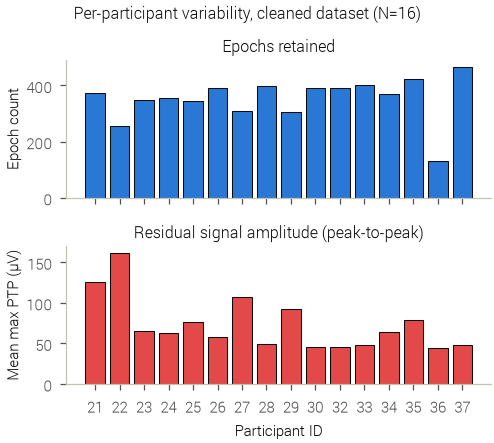

In [19]:
eeg_data_all = epochs.copy().pick('eeg').get_data() * 1e6  # (n_epochs, n_ch, n_times)
ptp = eeg_data_all.max(axis=2) - eeg_data_all.min(axis=2)   # (n_epochs, n_ch)
ptp_max = ptp.max(axis=1)                                   # worst channel per epoch, microvolts
md_ptp = md.copy()
md_ptp['ptp_uv'] = ptp_max

per_subj_count = md.groupby('subject').size()
per_subj_ptp = md_ptp.groupby('subject')['ptp_uv'].mean()
subj_order = sorted(per_subj_count.index, key=lambda s: int(s.split('_')[1]))

fig, axes = plt.subplots(2, 1, figsize=(COL_W, 3.0), sharex=True, layout='constrained')
ax = axes[0]
ax.bar([s.replace('subject_', '') for s in subj_order], per_subj_count.loc[subj_order],
       color=CAT_COLORS[0], edgecolor=INK_PRIMARY, linewidth=0.5)
ax.set_ylabel('Epoch count')
ax.set_title('Epochs retained')
clean_axes(ax)

ax = axes[1]
ax.bar([s.replace('subject_', '') for s in subj_order], per_subj_ptp.loc[subj_order],
       color=CAT_COLORS[7], edgecolor=INK_PRIMARY, linewidth=0.5)
ax.set_xlabel('Participant ID')
ax.set_ylabel('Mean max PTP (\u00b5V)')
ax.set_title('Residual signal amplitude (peak-to-peak)')
clean_axes(ax)
fig.suptitle(f'Per-participant variability, cleaned dataset (N={len(subj_order)})')
savefig(fig, 'persubject_variability.pdf')
plt.show()

**Figure: EEGNet LOSO accuracy vs. AutoReject drop rate, per participant.** Top left: accuracy of the EEGNet leave-one-subject-out model on each held-out participant (dashed line = mean majority-class chance). Bottom left: share of that participant's epochs dropped by AutoReject, counting only the `PINCH` + `Empty` epochs the cached LOSO run is trained and tested on (`FingerMovement` epochs were added to the dataset after that run and are excluded here) (`data/epoch_dataset` before vs. `data/epoch_dataset_filtered` after). Right: accuracy against drop rate, with an ordinary least-squares fit and Pearson / Spearman correlations (n = one point per participant). A drop rate normalizes for how many trials each participant recorded, so it measures data quality rather than data quantity.

*Based on: `data/results/eegnet_leave_one_out_run.pkl` (the base EEGNet LOSO run from `14_classification.ipynb`), per-fold accuracy computed the same way as `thesis_analysis/16_feedback_and_significance_analysis.ipynb`, Task 1; drop rate from the same lazily-read epoch metadata (`md_pre`, `md_post_lazy`) as the AutoReject rejection-rate figure in Part 1.*

            accuracy  chance  n_pre  n_post  drop_pct
subject                                              
subject_21    0.7061  0.5463    366     313   14.4809
subject_22    0.6712  0.5360    324     222   31.4815
subject_23    0.7324  0.5423    303     284    6.2706
subject_24    0.6254  0.5284    363     299   17.6309
subject_25    0.6267  0.5103    381     292   23.3596
subject_26    0.6553  0.5342    347     322    7.2046
subject_27    0.5703  0.5019    388     263   32.2165
subject_28    0.6829  0.5396    360     328    8.8889
subject_29    0.7121  0.5681    352     257   26.9886
subject_30    0.6535  0.5289    355     329    7.3239
subject_32    0.7562  0.5463    339     324    4.4248
subject_33    0.6136  0.5074    365     339    7.1233
subject_34    0.6710  0.5212    360     307   14.7222
subject_35    0.5815  0.5449    403     356   11.6625
subject_36    0.7938  0.5361     97      97    0.0000
subject_37    0.7128  0.5186    382     376    1.5707

Pearson r = -0.487 (p = 0.0

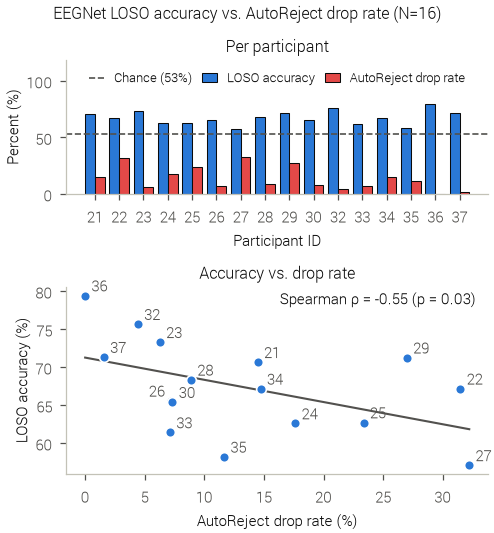

In [20]:
from scipy.stats import pearsonr, spearmanr

eegnet_loso = load_cached('eegnet_leave_one_out_run')

loso_rows = []
for subj, fold in eegnet_loso.items():
    y_true = fold['test_metadata']['EventType'].to_numpy()
    y_pred = np.asarray(fold['result']['y_pred'])
    assert len(y_true) == len(y_pred), f'{subj}: y_true/y_pred length mismatch'
    loso_rows.append(dict(
        subject=subj,
        accuracy=float((y_true == y_pred).mean()),
        n_test=len(y_true),
        chance=max((y_true == 'PinchLog').mean(), (y_true == 'NoPinchLog').mean()),
    ))
loso_subj = pd.DataFrame(loso_rows).set_index('subject')

# AutoReject drop rate on the same epoch subset the cached LOSO run uses: PINCH pinches + Empty
# negatives (FingerMovement epochs postdate that run, so they are left out)
def loso_subset_counts(m):
    keep = ((m['EventType'] == 'PinchLog') & (m['PinchType'] == 'PINCH')) |            ((m['EventType'] == 'NoPinchLog') & (m['PinchType'] == 'Empty'))
    return m[keep].groupby('subject').size()

loso_subj['n_pre'] = loso_subset_counts(md_pre)
loso_subj['n_post'] = loso_subset_counts(md_post_lazy)
loso_subj['drop_pct'] = 100 * (1 - loso_subj['n_post'] / loso_subj['n_pre'])
mismatch = loso_subj.index[loso_subj['n_post'] != loso_subj['n_test']].tolist()
if mismatch:
    print(f'WARNING: post-AutoReject counts differ from the LOSO test-fold sizes for {mismatch} '
          f'(epoch_dataset_filtered changed since the LOSO run?)')
loso_subj = loso_subj.sort_index(key=lambda s: [int(x.split('_')[1]) for x in s])

r_p, p_p = pearsonr(loso_subj['drop_pct'], loso_subj['accuracy'])
r_s, p_s = spearmanr(loso_subj['drop_pct'], loso_subj['accuracy'])
print(loso_subj[['accuracy', 'chance', 'n_pre', 'n_post', 'drop_pct']].round(4))
print(f'\nPearson r = {r_p:.3f} (p = {p_p:.3g}),  Spearman rho = {r_s:.3f} (p = {p_s:.3g}),  '
      f'n = {len(loso_subj)} participants')

ids = [s.replace('subject_', '') for s in loso_subj.index]
x = np.arange(len(loso_subj))
chance_mean = loso_subj['chance'].mean()

acc_pct = 100 * loso_subj['accuracy']
chance_pct = 100 * chance_mean

fig = plt.figure(figsize=(COL_W, 3.6), layout='constrained')
gs = fig.add_gridspec(2, 1, height_ratios=[1, 1.4])
ax_b = fig.add_subplot(gs[0])
ax_sc = fig.add_subplot(gs[1])

# accuracy and drop rate are both percentages, so they share one y axis
w = 0.4
ax_b.bar(x - w / 2, acc_pct, w, color=CAT_COLORS[0], edgecolor=INK_PRIMARY, linewidth=0.5, label='LOSO accuracy')
ax_b.bar(x + w / 2, loso_subj['drop_pct'], w, color=CAT_COLORS[7], edgecolor=INK_PRIMARY, linewidth=0.5,
         label='AutoReject drop rate')
ax_b.axhline(chance_pct, color=INK_SECONDARY, linestyle='--', linewidth=0.8, label=f'Chance ({chance_pct:.0f}%)')
ax_b.set_xticks(x)
ax_b.set_xticklabels(ids)
ax_b.set_xlabel('Participant ID')
ax_b.set_ylabel('Percent (%)')
ax_b.set_ylim(0, 118)  # headroom for the legend
ax_b.legend(frameon=False, loc='upper center', ncols=3, handlelength=1.2, columnspacing=0.8)
ax_b.set_title('Per participant')
clean_axes(ax_b)

ax_sc.scatter(loso_subj['drop_pct'], acc_pct, s=22, color=CAT_COLORS[0],
              edgecolor='white', linewidth=0.8, zorder=3)
slope, intercept = np.polyfit(loso_subj['drop_pct'], acc_pct, 1)
xs = np.linspace(loso_subj['drop_pct'].min(), loso_subj['drop_pct'].max(), 50)
ax_sc.plot(xs, slope * xs + intercept, color=INK_SECONDARY, linewidth=1, zorder=2)
# label each point with its participant ID; when another point sits just to its right (close
# enough that right-hand labels would collide), put this point's label on its left instead
x_close = 0.05 * (loso_subj['drop_pct'].max() - loso_subj['drop_pct'].min())
pts = list(zip(ids, loso_subj['drop_pct'], acc_pct))
for sid, d_, acc_ in pts:
    flip = any(0 < d2 - d_ < x_close and abs(a2 - acc_) < 1 for _, d2, a2 in pts)
    ax_sc.annotate(sid, (d_, acc_), xytext=(-3, 2) if flip else (3, 2), textcoords='offset points',
                   ha='right' if flip else 'left', color=INK_SECONDARY)
ax_sc.text(0.97, 0.99, f'Spearman \u03c1 = {r_s:.2f} (p = {p_s:.2f})',
           transform=ax_sc.transAxes, ha='right', va='top', color=INK_PRIMARY)
ax_sc.set_xlabel('AutoReject drop rate (%)')
ax_sc.set_ylabel('LOSO accuracy (%)')
ax_sc.set_title('Accuracy vs. drop rate')
clean_axes(ax_sc)

fig.suptitle(f'EEGNet LOSO accuracy vs. AutoReject drop rate (N={len(loso_subj)})')
savefig(fig, 'persubject_loso_accuracy_vs_droprate.pdf')
plt.show()

## Summary

All figures were written to `out_thesis/figs/pub/`:

**Part 1 (recreations, paper style):**
1. `dataquality_session_duration.pdf` - mean recording duration by session
2. `dataquality_marker_counts.pdf` - mean marker volume by event type
3. `dataquality_pinchtype_counts.pdf` - mean pinch-event outcome by type (bug-fixed)
4. `dataquality_autoreject_droprate.pdf` - AutoReject rejection rate by participant (substitute for the structurally-empty bad-electrode panel)
5. `erp_pinch_vs_nopinch.pdf` - grand-average ERP, Pinch vs. No-Pinch, C3/Cz
6. `topomap_pinch_sequence.pdf` - topomap sequence, PINCH trials
7. `model_comparison_by_split.pdf` - model x split (Mixed/LOSO/Cross-Session) accuracy

**Part 2 (new figures):**
8. `freevar_erp_spn_smallmultiples.pdf` - visual/auditory feedback + virtual hand ERP comparison at the SPN electrodes where all three modalities enlarge the late SPN, small multiples
9. `freevar_epoch_counts.pdf` - class balance of the boolean free variables
10. `numberofstimuli_layout.pdf` - stimulus-layout size: counts + ERP by layout
11. `dataset_session1_vs_session2.pdf` - session 1 vs. 2: counts + class balance
12. `dataset_before_after_autoreject.pdf` - per-subject epoch counts, before vs. after AutoReject
13. `persubject_variability.pdf` - per-subject epoch counts + mean peak-to-peak amplitude
14. `persubject_loso_accuracy_vs_droprate.pdf` - per-subject EEGNet LOSO accuracy vs. AutoReject drop rate, with correlation